# GitHub version

date

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Set the font family and size to use for Matplotlib figures.
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12

In [3]:
def advance_linear_convection(u0, c, dx, dt, num_steps):
    '''Advance linear convection with the FTBS scheme.'''
    u = u0.copy()
    for n in range(num_steps):
        u[1:] = u[1:] - c * dt / dx * (u[1:] - u[:-1])
    return u

In [4]:
L = 2.0
c = 1.0
dt = 0.02
nx_trials = [41, 81, 101, 121]

print(f"{'nx':>5} {'dx':>10} {'C':>8}")
for nx in nx_trials:
    dx = L / (nx - 1)
    courant = c * dt / dx
    print(f'{nx:5d} {dx:10.5f} {courant:8.3f}')

   nx         dx        C
   41    0.05000    0.400
   81    0.02500    0.800
  101    0.02000    1.000
  121    0.01667    1.200


In [5]:
num_steps = 25
perturbation = 1e-3
nx_perturbation = [81, 101, 121]
time = dt * np.arange(num_steps + 1)
error_histories = []
courant_numbers = []

In [6]:
for nx in nx_perturbation:
    dx = L / (nx - 1)
    courant = c * dt / dx

    u_a = np.ones(nx)
    u_b = u_a.copy()
    u_b[nx // 4] += perturbation

    error = np.empty(num_steps + 1)
    error[0] = np.max(np.abs(u_b - u_a))
    for n in range(num_steps):
        u_a = advance_linear_convection(u_a, c, dx, dt, 1)
        u_b = advance_linear_convection(u_b, c, dx, dt, 1)
        error[n + 1] = np.max(np.abs(u_b - u_a))

    error_histories.append(error)
    courant_numbers.append(courant)

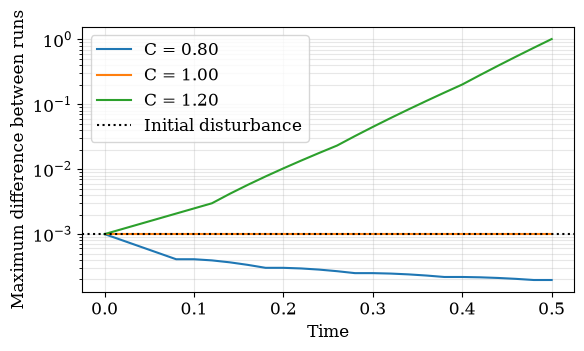

In [7]:
fig, ax = plt.subplots(figsize=(6.0, 3.5))
for courant, error in zip(courant_numbers, error_histories):
    ax.semilogy(time, error, label=f'C = {courant:.2f}')

ax.axhline(perturbation, color='black', linestyle=':',
           label='Initial disturbance')
ax.set_xlabel('Time')
ax.set_ylabel('Maximum difference between runs')
ax.grid(which='both', alpha=0.3)
ax.legend()
fig.tight_layout();

In [8]:
steps_to_report = [1, 5, 10, 25]
print(f"{'C':>6}" + ''.join(
    f'{str(step) + " steps":>14}' for step in steps_to_report
))
for courant, error in zip(courant_numbers, error_histories):
    print(f'{courant:6.2f}' + ''.join(
        f'{error[step]:14.2e}' for step in steps_to_report
    ))

     C       1 steps       5 steps      10 steps      25 steps
  0.80      8.00e-04      4.10e-04      3.02e-04      1.96e-04
  1.00      1.00e-03      1.00e-03      1.00e-03      1.00e-03
  1.20      1.20e-03      2.49e-03      1.03e-02      1.02e+00


## Original Solver


In [9]:
u_demo = np.array([1.0, 2.0, 1.0, 1.0])

# A step beyond the stability bound.
print('C > 1:       ', advance_linear_convection(
    u_demo, c=1.0, dx=1.0, dt=1.2, num_steps=1))

# A negative speed with the same backward-space update.
print('Negative c:  ', advance_linear_convection(
    u_demo, c=-1.0, dx=1.0, dt=0.2, num_steps=1))

# Integer storage for a calculation with fractional updates.
print('Integer u0:  ', advance_linear_convection(
    u_demo.astype(int), c=1.0, dx=1.0, dt=0.2, num_steps=1))

# A spacing inconsistent with the grid on which u_demo was defined.
print('Wrong dx:    ', advance_linear_convection(
    u_demo, c=1.0, dx=2.0, dt=0.2, num_steps=1))

C > 1:        [1.  0.8 2.2 1. ]
Negative c:   [1.  2.2 0.8 1. ]
Integer u0:   [1 1 1 1]
Wrong dx:     [1.  1.9 1.1 1. ]


**Example Brief Instructions**

Outcome: What calculation should this solver deliver?
Context and assumptions: What equation, grid, and boundary model does it support?


Interface and outputs: Copy the signature and define every returned field.


Required behavior: State the update, direction selection, time selection,
    copying rules, and zero-evolution cases
    
Rejected requests: List invalid inputs and the required exception behavior.

Acceptance evidence: Map each requirement to a hand result, invariant,
    comparison, or rejected-call test.
    
Agent permissions: State what the agent may add and what it must preserve.

# Agent Task Brief:

## 1. Outcome


Implement `solve_transport` that solves the 1D linear advection equation on a uniform spatial grid.
The solver must:

* Automatically choose a stable time step using the target Courant number courant.
* Run the simulation until the requested final time without stopping early or going past it.
* Choose the correct numerical method depending on whether the velocity c is positive or negative.
* The solver must not change the value at the boundary where the flow enters the grid.
* Handle cases where no calculations are needed (c = 0 or t_final = 0).
* Return the final solution and information about the simulation in a dictionary

---

## 2. Context and Assumptions

### Governing Equation
$$\frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} = 0$$

Where:
- $u$ = transported scalar quantity.
- $c$ = constant transport velocity.
- $x$ = spatial coordinate.
- $t$ = time.

### Grid Assumptions
- Domain endpoints: `x_limits = (x_min, x_max)`.
- Initial values: `u0` at equally spaced grid points ($N = \text{len}(u0) \ge 2$).
- Uniform grid spacing:
  $$\Delta x = \frac{x_{\text{max}} - x_{\text{min}}}{N - 1}$$

The solver does not check if the caller sampled `u0` at exact grid locations.

### Boundary Assumptions
- Constant Dirichlet inflow boundaries:
  - Positive velocity ($c > 0$): Left boundary fixed ($u_0^{n+1} = u0[0]$).
  - Negative velocity ($c < 0$): Right boundary fixed ($u_{N-1}^{n+1} = u0[-1]$).
- Downstream boundaries updated via upwind stencils.

### Scope Limitations
- Uniform grids, constant velocity $c$, and fixed inflow boundaries only.
- Variable velocities, non-uniform grids, and dynamic boundary values are outside solver scope.

Assume ordinary real numeric lists, NumPy arrays, and scalar parameters with magnitudes for which grid and time-step calculations are representable in floating point. General-purpose type validation and special handling of extreme floating-point ranges are not required.

---

## 3. Interface and Outputs

### Signature
```python
solve_transport(u0, x_limits, c, t_final, courant=0.8, max_steps=100_000)

```

### Returned Dictionary Fields

| Key | Data Type | Definition & Formula |
| --- | --- | --- |
| **`"x"`** | `np.ndarray` | 1D spatial grid array of shape $(N,)$ from $x_{\text{min}}$ to $x_{\text{max}}$ inclusive (`float64`). |
| **`"u"`** | `np.ndarray` | Final numerical solution array of shape $(N,)$ representing $u(x, t_{\text{final}})$ (`float64`). |
| **`"t_final"`** | `float` | Exact target simulation time requested. |
| **`"dx"`** | `float` | Uniform grid spacing $\Delta x = \frac{x_{\text{max}} - x_{\text{min}}}{N - 1}$. |
| **`"dt"`** | `float` | Actual time step $\Delta t = \frac{t_{\text{final}}}{N_{\text{steps}}}$ used (*`0.0` for zero-evolution*). |
| **`"num_steps"`** | `int` | Completed time update iterations $N_{\text{steps}} = \left\lceil \frac{t_{\text{final}}}{\Delta t_{\text{max}}} \right\rceil$ (*`0` for zero-evolution*). |
| **`"courant"`** | `float` | Realized **signed** Courant number $C = \frac{c \, \Delta t}{\Delta x}$ (*`0.0` for zero-evolution*). |

---

## 4. Required Behavior

### Numerical Updates & Upwind Direction Selection

1. **Positive Velocity ($c > 0$) — First-Order Backward Space (FTBS):**

$$u_i^{n+1} = (1 - C) u_i^n + C u_{i-1}^n \quad \text{for } i \in [1, N-1]$$


* Fixed left boundary: $u_0^{n+1} = u0[0]$.
* Signed realized Courant: $C = \frac{c \, \Delta t}{\Delta x} > 0$.


2. **Negative Velocity ($c < 0$) — First-Order Forward Space (FTFS):**

$$u_i^{n+1} = (1 + C) u_i^n - C u_{i+1}^n \quad \text{for } i \in [0, N-2]$$


* Fixed right boundary: $u_{N-1}^{n+1} = u0[-1]$.
* Signed realized Courant: $C = \frac{c \, \Delta t}{\Delta x} < 0$.



### Time Selection (Equation 23)

Given target Courant magnitude `courant` ($q \in (0, 1.0]$):

1. Maximum stable time step: $\Delta t_{\text{max}} = \frac{q \cdot \Delta x}{|c|}$
2. Step budget: $N_{\text{steps}} = \left\lceil \frac{t_{\text{final}}}{\Delta t_{\text{max}}} \right\rceil$
3. Actual time step: $\Delta t = \frac{t_{\text{final}}}{N_{\text{steps}}}$
4. Realized signed Courant number: $C = \frac{c \cdot \Delta t}{\Delta x}$

### Copy Rules & Memory Ownership

* Explicitly convert `u0` to an independent floating-point working array (`float64`).
* Caller's input array `u0` must remain unmodified.
* Returned arrays (`"x"` and `"u"`) must not share memory storage with `u0` (`np.shares_memory` is `False`).

### Zero Evolution Cases ($c = 0$ or $t_{\text{final}} = 0$)

After parameter checks pass:

* Perform `0` update iterations (`num_steps = 0`).
* Return an unchanged floating-point copy of `u0`.
* Set returned metadata: `dt = 0.0`, `num_steps = 0`, `courant = 0.0`.

---

## 5. Rejected Requests

Raise `ValueError` with a descriptive message before executing updates for any of the following:

| Input / Parameter | Invalid Condition | Purpose / Defect Addressed |
| --- | --- | --- |
| `u0` | Not 1D or contains $N < 2$ values | Prevents shape mismatch and invalid $\Delta x$ computation |
| `u0` | Contains non-finite values | Prevents corrupting floating-point update loops |
| `x_limits` | Not exactly two finite values or $x_{\text{min}} \ge x_{\text{max}}$ | Ensures valid positive spatial domain spacing $\Delta x > 0$ |
| `c` | Non-finite | Ensures valid scalar velocity |
| `t_final` | Non-finite or $t_{\text{final}} < 0$ | Prevents invalid or backward time integration |
| `courant` | Non-finite or outside $0 < \text{courant} \le 1.0$ | Prevents CFL numerical instability ($q > 1.0$) |
| `max_steps` | Not a positive integer | Ensures valid integer step budget limit |
| **Step Budget** | $N_{\text{steps}} > \text{max\_steps}$ | Prevents exceeding maximum allowable work budget |

---

## 6. Acceptance Evidence

| Requirement | Test Description & Specific Check |
| --- | --- |
| **Exact Shift Test ($c > 0$)** | Pass $u0 = [1, 2, 3, 4]$, $x_{\text{limits}} = (0, 3)$, $c = 1.0$, $t_{\text{final}} = 1.0$, $q = 1.0$. Verify returned `"u"` matches hand-calculated `[1, 1, 2, 3]`. |
| **Reverse Advection Test ($c < 0$)** | Pass $u0 = [1, 2, 3, 4]$, $x_{\text{limits}} = (0, 3)$, $c = -1.0$, $t_{\text{final}} = 0.2$, $q = 0.2$. Verify single FTFS step matches `[1.2, 2.2, 3.2, 4.0]`. |
| **Grid Construction** | Verify `"x"` includes $x_{\text{min}}$ and $x_{\text{max}}$, length equals $\text{len}(u0)$, and `"dx"` equals $\frac{x_{\text{max}} - x_{\text{min}}}{N - 1}$. |
| **Time Selection & Courant Realization** | Verify `"num_steps"` equals $N_{\text{steps}}$, `"dt"` equals $\frac{t_{\text{final}}}{N_{\text{steps}}}$, and `"courant"` equals $\frac{c \, \Delta t}{\Delta x}$. |
| **Inflow Boundary Invariants** | Assert $u[0] == u0[0]$ for $c > 0$, and $u[-1] == u0[-1]$ for $c < 0$ after completion. |
| **Zero-Evolution Handlers** | Test $c = 0$ or $t_{\text{final}} = 0$. Assert returned `"u"` equals `u0`, `"num_steps"` is `0`, `"dt"` is `0.0`, and `"courant"` is `0.0`. |
| **Memory Isolation & Ownership** | Assert `np.shares_memory(result['u'], u0)` is `False` and `u0` remains unmodified. |
| **Refused-Input Tests** | Verify `ValueError` is raised for invalid shapes, non-finites, $x_{\text{min}} \ge x_{\text{max}}$, $t_{\text{final}} < 0$, $q \notin (0, 1.0]$, or $N_{\text{steps}} > \text{max\_steps}$. |

---

## 7. Agent Permissions

### What You May Add

* Python loops and NumPy vectorization to update grid values.
* Defensive checks to catch invalid inputs and step budget overruns.
* Descriptive error messages inside `ValueError`.

### What You Must Keep & Assume

* **Standard Inputs:** Assume ordinary numbers, lists, and NumPy arrays.
* **No Extra Code:** Do not add general-purpose type validation or extreme floating-point handling.
* **Target Courant:** Treat `courant` strictly as target magnitude $q$, not signed $C$.
* **Exact Signature:** Keep `solve_transport(u0, x_limits, c, t_final, courant=0.8, max_steps=100_000)`.
* **Exact Outputs:** Return strictly the 7 specified keys (`x`, `u`, `t_final`, `dx`, `dt`, `num_steps`, `courant`).
* **Exact Time:** Land on $t_{\text{final}}$ exactly using $\Delta t = \frac{t_{\text{final}}}{N_{\text{steps}}}$.
* **No Side Effects:** Do not modify `u0` or share memory storage with returned arrays.
* **Simple Model:** Stick strictly to 1D linear advection with constant speed and fixed inflows.

```

```

In [12]:
import math
import numpy as np


def solve_transport(u0, x_limits, c, t_final, courant=0.8, max_steps=100_000):
    '''Solve constant-speed 1D advection with fixed inflow and upwind steps.

    Use an independent float64 copy of u0 on the uniform x_limits grid.
    Return x, u, t_final, dx, dt, num_steps, and the signed realized courant.
    Invalid contract inputs or an exceeded step budget raise ValueError.
    '''
    u = np.array(u0, dtype=np.float64, copy=True)
    if u.ndim != 1 or u.size < 2:
        raise ValueError('u0 must be one-dimensional with at least two values')
    if not np.all(np.isfinite(u)):
        raise ValueError('u0 must contain only finite values')

    limits = np.asarray(x_limits, dtype=np.float64)
    if limits.shape != (2,) or not np.all(np.isfinite(limits)):
        raise ValueError('x_limits must contain exactly two finite values')
    x_min, x_max = map(float, limits)
    if x_min >= x_max:
        raise ValueError('x_limits must satisfy x_min < x_max')
    if not np.isfinite(c):
        raise ValueError('c must be finite')
    if not np.isfinite(t_final) or t_final < 0:
        raise ValueError('t_final must be finite and nonnegative')
    if not np.isfinite(courant) or not 0 < courant <= 1:
        raise ValueError('courant must be finite and satisfy 0 < courant <= 1')
    if (isinstance(max_steps, (bool, np.bool_))
            or not isinstance(max_steps, (int, np.integer))
            or max_steps <= 0):
        raise ValueError('max_steps must be a positive integer')

    c = float(c)
    t_final = float(t_final)
    courant = float(courant)
    dx = (x_max - x_min) / (u.size - 1)
    x = np.linspace(x_min, x_max, u.size, dtype=np.float64)
    dt = 0.0
    num_steps = 0
    C = 0.0

    if c != 0 and t_final != 0:
        dt_max = courant * dx / abs(c)
        num_steps = math.ceil(t_final / dt_max)
        if num_steps > max_steps:
            raise ValueError('Required number of steps exceeds max_steps budget')
        dt = t_final / num_steps
        C = c * dt / dx
        if c > 0:
            for _ in range(num_steps):
                # FTBS: the left inflow stays fixed; RHS uses the old values.
                u[1:] = (1 - C) * u[1:] + C * u[:-1]
        else:
            for _ in range(num_steps):
                # FTFS: the right inflow stays fixed; RHS uses the old values.
                u[:-1] = (1 + C) * u[:-1] - C * u[1:]

    return {
        'x': x, 'u': u, 't_final': t_final, 'dx': dx,
        'dt': dt, 'num_steps': num_steps, 'courant': C,
    }


In [13]:
import numpy as np


def run_solver_checks(solver):
    '''Check a supplied solver using hand results and contract assertions.'''
    def check_result(initial, limits, speed, target, expected_u,
                     expected_x, dx, dt, steps, signed_c, **options):
        before = np.array(initial, copy=True)
        result = solver(initial, limits, speed, target, **options)
        assert isinstance(result, dict)
        assert set(result) == {
            'x', 'u', 't_final', 'dx', 'dt', 'num_steps', 'courant'
        }
        for key in ('x', 'u'):
            assert isinstance(result[key], np.ndarray)
            assert result[key].shape == before.shape
            assert result[key].dtype == np.dtype('float64')
            assert not np.shares_memory(result[key], initial)
        for key in ('t_final', 'dx', 'dt', 'courant'):
            assert type(result[key]) is float, key
        assert type(result['num_steps']) is int
        assert result['t_final'] == target
        assert result['num_steps'] == steps
        np.testing.assert_allclose(
            [result['dx'], result['dt'], result['courant']],
            [dx, dt, signed_c], rtol=1e-13, atol=1e-14)
        np.testing.assert_allclose(result['x'], expected_x, rtol=0, atol=1e-14)
        np.testing.assert_allclose(result['u'], expected_u,
                                   rtol=1e-13, atol=1e-14)
        np.testing.assert_array_equal(initial, before)
        if speed > 0:
            assert result['u'][0] == before[0]
        elif speed < 0:
            assert result['u'][-1] == before[-1]
        if steps:
            np.testing.assert_allclose(steps * result['dt'], target,
                                       rtol=1e-13, atol=1e-14)
            assert abs(result['courant']) <= options.get('courant', 0.8)
        else:
            assert result['dt'] == result['courant'] == 0.0
            np.testing.assert_array_equal(result['u'], before)

    # The two independent hand results supplied in the brief.
    check_result([1, 2, 3, 4], (0, 3), 1.0, 1.0,
                 [1, 1, 2, 3], [0, 1, 2, 3], 1.0, 1.0, 1, 1.0,
                 courant=1.0, max_steps=1)
    check_result(np.array([1, 2, 3, 4]), (0, 3), -1.0, 0.2,
                 [1.2, 2.2, 3.2, 4.0], [0, 1, 2, 3],
                 1.0, 0.2, 1, -0.2, courant=0.2)

    # Default q=0.8 gives two half-time steps, not one full step.
    # Hand values after two C=+/-0.5 steps; shifted grid has dx=2.
    for speed, expected, signed_c in (
        (2.0, [1, 1.25, 2, 3], 0.5),
        (-2.0, [2, 3, 3.75, 4], -0.5),
    ):
        check_result(np.array([1., 2., 3., 4.]), (-2, 4), speed, 1.0,
                     expected, [-2, 0, 2, 4], 2.0, 0.5, 2, signed_c,
                     max_steps=2)

    for speed, target in ((0.0, 5.0), (1.0, 0.0), (-1.0, 0.0)):
        check_result(np.array([1., 2., 3., 4.]), (0, 3), speed, target,
                     [1, 2, 3, 4], [0, 1, 2, 3], 1.0, 0.0, 0, 0.0,
                     max_steps=1)

    # Each message must identify the parameter and explain its requirement.
    # Alternative fragments allow descriptive wording without exact matching.
    refused = [
        ({'u0': [[1, 2], [3, 4]]}, ('u0', 'initial'), ('1d', 'one', 'dimension')),
        ({'u0': []}, ('u0', 'initial'), ('two', '2', 'length', 'size')),
        ({'u0': [1]}, ('u0', 'initial'), ('two', '2', 'length', 'size')),
        ({'u0': [1, np.nan]}, ('u0', 'initial'), ('finite', 'nan')),
        ({'u0': [1, np.inf]}, ('u0', 'initial'), ('finite', 'inf')),
        ({'x_limits': [0]}, ('x_limits', 'domain', 'endpoint'), ('two', '2', 'length')),
        ({'x_limits': [0, 1, 2]}, ('x_limits', 'domain', 'endpoint'), ('two', '2', 'length')),
        ({'x_limits': [0, np.inf]}, ('x_limits', 'domain', 'endpoint'), ('finite', 'inf')),
        ({'x_limits': [np.nan, 3]}, ('x_limits', 'domain', 'endpoint'), ('finite', 'nan')),
        ({'x_limits': [3, 3]}, ('x_limits', 'domain', 'endpoint'), ('<', 'increas', 'greater', 'less', 'positive')),
        ({'x_limits': [3, 0]}, ('x_limits', 'domain', 'endpoint'), ('<', 'increas', 'greater', 'less', 'positive')),
        ({'t_final': -1}, ('t_final', 'time'), ('nonnegative', 'non-negative', '>=', 'negative')),
    ]
    for value in (np.nan, np.inf, -np.inf):
        refused.extend([
            ({'c': value}, ('c', 'speed', 'velocity'), ('finite', 'nan', 'inf')),
            ({'t_final': value}, ('t_final', 'time'), ('finite', 'nan', 'inf')),
            ({'courant': value}, ('courant', 'cfl'), ('finite', 'nan', 'inf')),
        ])
    for value in (0, -0.2, 1.2):
        refused.append(({'courant': value}, ('courant', 'cfl'),
                        ('0', '1', 'positive', 'range')))
    for value in (0, -1, 1.5, 2.0, True):
        refused.append(({'max_steps': value}, ('max_steps', 'step'),
                        ('positive', 'integer')))
    refused.append(({'max_steps': 1}, ('max_steps', 'step'),
                    ('exceed', 'budget', 'limit', 'maximum')))

    for changes, parameter_words, requirement_words in refused:
        # Repeat invalid parameter checks in each zero-evolution branch.
        # Budget overrun alone requires nonzero evolution.
        modes = ({},) if changes == {'max_steps': 1} else (
            {}, {'c': 0.0}, {'t_final': 0.0})
        for mode in modes:
            args = dict(u0=np.array([1., 2., 3., 4.]),
                        x_limits=(0, 3), c=1.0, t_final=1.0,
                        courant=0.8, max_steps=100_000)
            args.update(mode)
            args.update(changes)
            before = np.array(args['u0'], copy=True)
            try:
                solver(**args)
            except ValueError as error:
                message = str(error).lower()
                assert any(word in message for word in parameter_words), message
                assert any(word in message for word in requirement_words), message
            else:
                raise AssertionError(f'Expected ValueError for {args!r}')
            np.testing.assert_array_equal(args['u0'], before)


Tests are callable through `run_solver_checks(solver)`; no checks have been executed.

- The brief's exact shift and reverse-advection hand results check both stencils, downstream updates, and fixed inflows.
- Two hand-calculated half-step cases check ceiling-based final-time selection, default Courant magnitude, both signed realized Courant numbers, and a shifted grid with nonunit spacing.
- Shared assertions check all seven fields, types, grid values, time metadata, unchanged inputs, and memory isolation. Zero-speed and zero-time cases check unchanged float64 copies and zero-step metadata.
- Refused calls check `ValueError` and descriptive message fragments for every rejection category, including checks before zero evolution and a step-budget overrun; accepted cases also exercise the exact budget limit.

Limitations: uniform grids, constant real speed, and fixed inflows only; actual input sampling locations are not verified. General-purpose type validation, mixed Boolean data, extreme floating-point ranges, and roundoff-triggered step-count adjustments are outside the contract. These small checks are not an exhaustive accuracy or convergence study.

**One Positive step**

In [16]:
u0 = np.array([1.0, 2.0, 3.0, 4.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 3),
    c=1.0,
    t_final=0.2,
    courant=1.0
)

print(result)

{'x': array([0., 1., 2., 3.]), 'u': array([1. , 1.8, 2.8, 3.8]), 't_final': 0.2, 'dx': 1.0, 'dt': 0.2, 'num_steps': 1, 'courant': 0.2}


**One Negative Step**

In [17]:
u0 = np.array([1.0, 2.0, 3.0, 4.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 3),
    c=-1.0,
    t_final=0.2,
    courant=1.0
)

print(result)

{'x': array([0., 1., 2., 3.]), 'u': array([1.2, 2.2, 3.2, 4. ]), 't_final': 0.2, 'dx': 1.0, 'dt': 0.2, 'num_steps': 1, 'courant': -0.2}


**Exact Shifts** (compared to written down values)

In [18]:
u0 = np.array([1.0, 2.0, 3.0, 4.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 3),
    c=1.0,
    t_final=1,
    courant=1.0
)

print(result)

{'x': array([0., 1., 2., 3.]), 'u': array([1., 1., 2., 3.]), 't_final': 1.0, 'dx': 1.0, 'dt': 1.0, 'num_steps': 1, 'courant': 1.0}


In [19]:
u0 = np.array([1.0, 2.0, 3.0, 4.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 3),
    c=-1.0,
    t_final=1,
    courant=1.0
)

print(result)

{'x': array([0., 1., 2., 3.]), 'u': array([2., 3., 4., 4.]), 't_final': 1.0, 'dx': 1.0, 'dt': 1.0, 'num_steps': 1, 'courant': -1.0}


**Final-time selection** (Enter 5 inital values instead of 4, see a change in dx)

In [22]:
u0 = np.array([1.0, 2.0, 1.0, 1.0, 1.0]) # Enter 5 initial Values instead of 4

result = solve_transport(
    u0=u0,
    x_limits=(0, 1),
    c=1.0,
    t_final=0.55,
    courant=0.8
)

print(result)

{'x': array([0.  , 0.25, 0.5 , 0.75, 1.  ]), 'u': array([1.        , 1.01896296, 1.15644444, 1.43022222, 1.39437037]), 't_final': 0.55, 'dx': 0.25, 'dt': 0.18333333333333335, 'num_steps': 3, 'courant': 0.7333333333333334}


**Constant State** (used all 2 in array, U array didnt change)

In [23]:
u0 = np.array([2, 2, 2, 2])

result = solve_transport(
    u0=u0,
    x_limits=(0, 1),
    c=1.0,
    t_final=0.55,
    courant=0.8
)

print(result)

{'x': array([0.        , 0.33333333, 0.66666667, 1.        ]), 'u': array([2., 2., 2., 2.]), 't_final': 0.55, 'dx': 0.3333333333333333, 'dt': 0.18333333333333335, 'num_steps': 3, 'courant': 0.55}


**Integer Input**

In [25]:
u0 = np.array([1, 2, 3, 4])

result = solve_transport(
    u0=u0,
    x_limits=(0, 3),
    c=1.0,
    t_final=0.2,
    courant=0.2
)

print(result)

{'x': array([0., 1., 2., 3.]), 'u': array([1. , 1.8, 2.8, 3.8]), 't_final': 0.2, 'dx': 1.0, 'dt': 0.2, 'num_steps': 1, 'courant': 0.2}


**Ownership** (Same output as above, changed to float numbers instead of int) Copying rules

In [26]:
u0 = np.array([1.0, 2.0, 3.0, 4.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 3),
    c=1.0,
    t_final=0.2,
    courant=0.2
)

print(result)

{'x': array([0., 1., 2., 3.]), 'u': array([1. , 1.8, 2.8, 3.8]), 't_final': 0.2, 'dx': 1.0, 'dt': 0.2, 'num_steps': 1, 'courant': 0.2}


**Zero Evolution** (Valid inputs with zero speed or zero duration) due to courant equation $c* \triangle t$


In [27]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 2),
    c=0.0,
    t_final=1.0,
    courant=0.8
)

print(result)

{'x': array([0., 1., 2.]), 'u': array([1., 2., 3.]), 't_final': 1.0, 'dx': 1.0, 'dt': 0.0, 'num_steps': 0, 'courant': 0.0}


In [28]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 2),
    c=1.0,
    t_final=0.0,
    courant=0.8
)

print(result)

{'x': array([0., 1., 2.]), 'u': array([1., 2., 3.]), 't_final': 0.0, 'dx': 1.0, 'dt': 0.0, 'num_steps': 0, 'courant': 0.0}


**Invalid Requests** (Try one-point, two-dimensional, and nonfinite states; reversed limits; negative duration; nonfinite speed; targets 0 and 1.2; a zero step budget)

One point array:

In [29]:
u0 = np.array([1.0])

result = solve_transport(u0, (0, 1), 1.0, 0.5)

ValueError: u0 must be one-dimensional with at least two values

Two dimension

In [30]:
u0 = np.array([[1.0, 2.0], [3.0, 4.0]])

result = solve_transport(u0, (0, 1), 1.0, 0.5)

ValueError: u0 must be one-dimensional with at least two values

Nonfinite initial Values:

In [31]:
u0 = np.array([1.0, np.nan, 3.0])

result = solve_transport(u0, (0, 2), 1.0, 0.5)

ValueError: u0 must contain only finite values

Reversed domain limits:

In [32]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(u0, (2, 0), 1.0, 0.5)

ValueError: x_limits must satisfy x_min < x_max

Negative Final Time:

In [33]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(u0, (0, 2), 1.0, -0.5)

ValueError: t_final must be finite and nonnegative

Nonfinite Velocity:

In [34]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(u0, (0, 2), np.inf, 0.5)

ValueError: c must be finite

Courant number of zero:

In [36]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(u0, (0, 2), 1.0, 0.5, courant=0.0)

ValueError: courant must be finite and satisfy 0 < courant <= 1

Courant Value of 1.2:

In [37]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(u0, (0, 2), 1.0, 0.5, courant=1.2)

ValueError: courant must be finite and satisfy 0 < courant <= 1

Zero step budget:

In [38]:
u0 = np.array([1.0, 2.0, 3.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 2),
    c=1.0,
    t_final=0.5,
    max_steps=0
)

ValueError: max_steps must be a positive integer

**Exceeded budget** (The three-step final-time case above with max_steps=2)

In [39]:
u0 = np.array([1.0, 2.0, 3.0, 4.0, 5.0])

result = solve_transport(
    u0=u0,
    x_limits=(0, 1),
    c=1.0,
    t_final=0.55,
    courant=0.8,
    max_steps=2
)

print(result)

ValueError: Required number of steps exceeds max_steps budget

In [40]:
def solve_transport_wrong_inflow(u0, x_limits, c, t_final,
                                 courant=0.8, max_steps=100_000):
    '''Deliberately impose the wrong inflow value for negative speed.'''
    result = solve_transport(u0, x_limits, c, t_final,
                             courant=courant, max_steps=max_steps)
    if c < 0 and result['num_steps'] > 0:
        result['u'][-1] = float(u0[0])
    return result

run_solver_checks(solve_transport_wrong_inflow)

AssertionError: 
Not equal to tolerance rtol=1e-13, atol=1e-14

Mismatched elements: 1 / 4 (25%)
Mismatch at index:
 [3]: 1.0 (ACTUAL), 4.0 (DESIRED)
Max absolute difference among violations: 3.
Max relative difference among violations: 0.75
 ACTUAL: array([1.2, 2.2, 3.2, 1. ])
 DESIRED: array([1.2, 2.2, 3.2, 4. ])